In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="darkgrid")
df = pd.read_csv('flights.csv', nrows=500000)

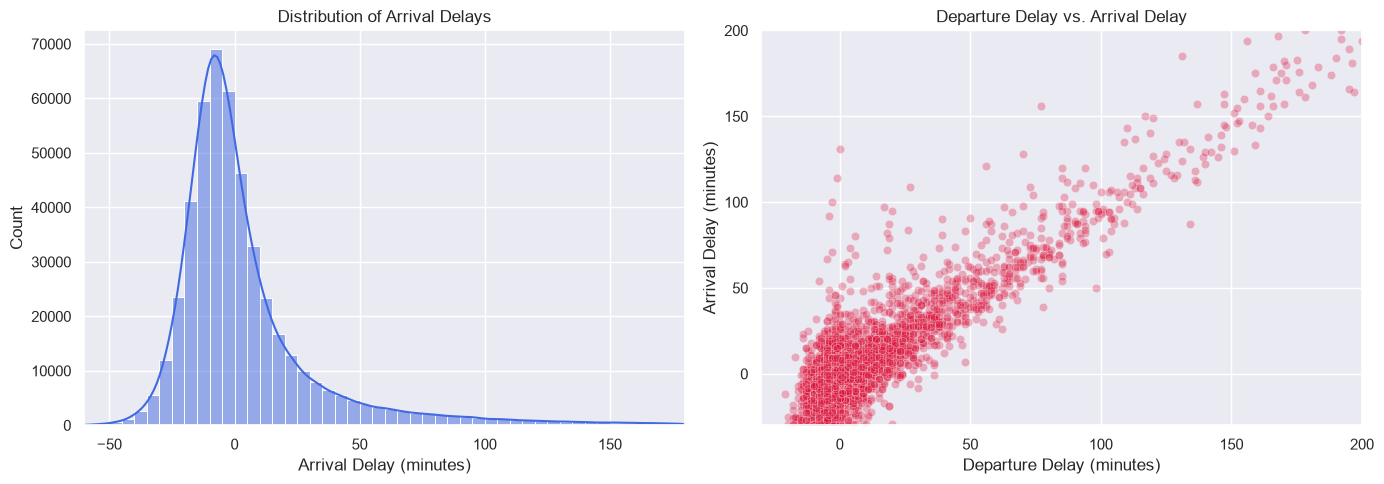

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df[df['ARRIVAL_DELAY'].between(-60, 180)]['ARRIVAL_DELAY'], bins=48, kde=True, ax=axes[0], color='royalblue')
axes[0].set_xlim(-60, 180)
axes[0].set_title('Distribution of Arrival Delays')
axes[0].set_xlabel('Arrival Delay (minutes)')

sns.scatterplot(x='DEPARTURE_DELAY', y='ARRIVAL_DELAY', data=df.sample(5000, random_state=42), ax=axes[1], alpha=0.3, color='crimson')
axes[1].set_xlim(-30, 200)
axes[1].set_ylim(-30, 200)
axes[1].set_title('Departure Delay vs. Arrival Delay')
axes[1].set_xlabel('Departure Delay (minutes)')
axes[1].set_ylabel('Arrival Delay (minutes)')

plt.tight_layout()
plt.show()

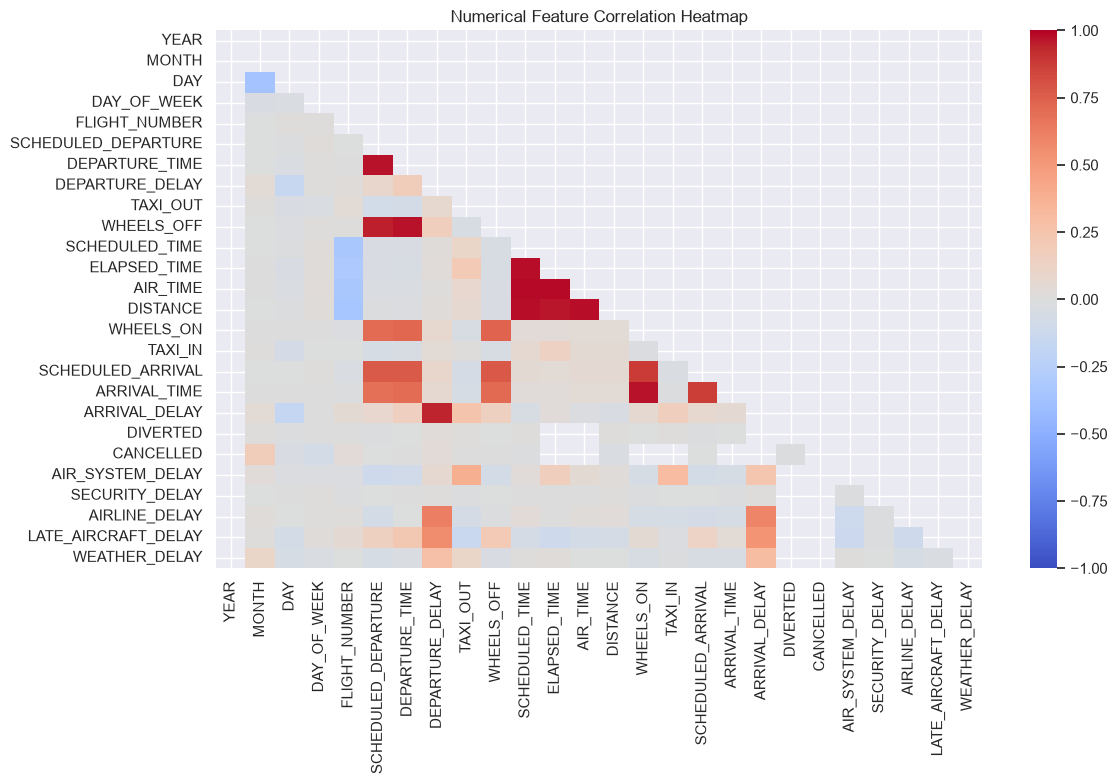

In [3]:
plt.figure(figsize=(12, 8))

num_df = df.select_dtypes(include=[np.number])
corr_matrix = num_df.corr()

mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Numerical Feature Correlation Heatmap')
plt.tight_layout()
plt.show()


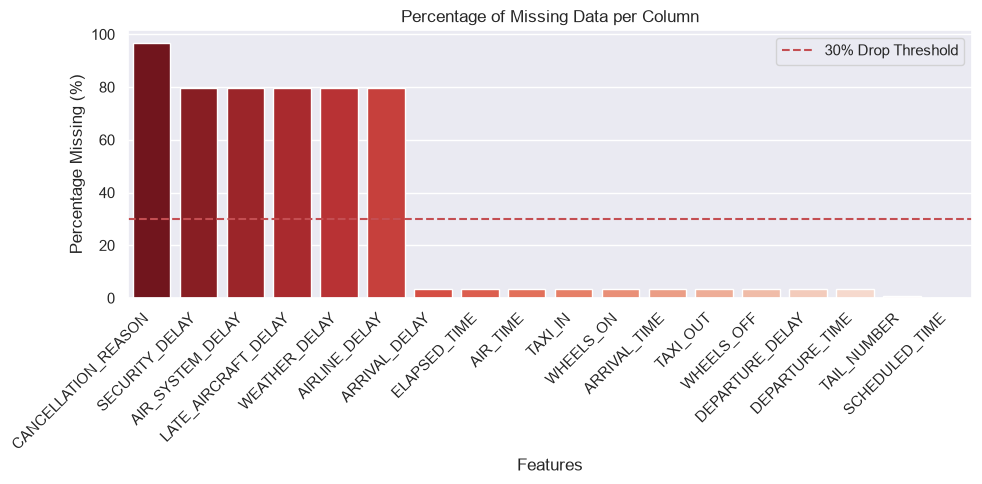

In [4]:
missing_pct = (df.isnull().sum() / len(df)) * 100
missing_pct = missing_pct[missing_pct > 0].sort_values(ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(x=missing_pct.index, y=missing_pct.values, hue=missing_pct.index, palette='Reds_r', legend=False)
plt.xticks(rotation=45, ha='right')
plt.xlabel('Features')
plt.ylabel('Percentage Missing (%)')
plt.title('Percentage of Missing Data per Column')
plt.axhline(y=30, color='r', linestyle='--', label='30% Drop Threshold')
plt.legend()
plt.tight_layout()
plt.show()

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, SplineTransformer, OneHotEncoder
from sklearn.feature_extraction.text import TfidfVectorizer

missing_cols_to_drop = [
    'CANCELLATION_REASON', 'SECURITY_DELAY', 'AIR_SYSTEM_DELAY', 
    'LATE_AIRCRAFT_DELAY', 'WEATHER_DELAY', 'AIRLINE_DELAY'
]
corr_cols_to_drop = [
    'YEAR', 'FLIGHT_NUMBER', 'TAIL_NUMBER',
    'DEPARTURE_TIME', 'WHEELS_OFF', 'WHEELS_ON', 'TAXI_IN',
    'ARRIVAL_TIME', 'ACTUAL_ELAPSED_TIME', 'ELAPSED_TIME'
]

df = df.drop(columns=missing_cols_to_drop + corr_cols_to_drop, errors='ignore')
df = df[(df['CANCELLED'] == 0) & (df['DIVERTED'] == 0)].copy()
df = df.drop(columns=['CANCELLED', 'DIVERTED'], errors='ignore')
df = df.dropna(subset=['ARRIVAL_DELAY'])

#  External Airport Mapping
map_code = pd.read_csv('L_AIRPORT.csv').astype(str).set_index('Code')['Description'].to_dict()
map_id = pd.read_csv('L_AIRPORT_ID.csv').astype(str).set_index('Code')['Description'].to_dict()
combined_map = {**map_code, **map_id}

df['ORIGIN_NAME'] = df['ORIGIN_AIRPORT'].astype(str).map(combined_map).fillna('Unknown Airport')
df['DEST_NAME'] = df['DESTINATION_AIRPORT'].astype(str).map(combined_map).fillna('Unknown Airport')

def hhmm_to_hours(series):
    series = series.fillna(0).astype(int)
    return (series // 100) + ((series % 100) / 60.0)

df['DEP_TIME_HOURS'] = hhmm_to_hours(df['SCHEDULED_DEPARTURE'])
df['ARR_TIME_HOURS'] = hhmm_to_hours(df['SCHEDULED_ARRIVAL'])

target_col = 'ARRIVAL_DELAY'
num_cols = ['MONTH', 'DAY_OF_WEEK', 'DEPARTURE_DELAY', 'TAXI_OUT', 'SCHEDULED_TIME', 'DISTANCE']
time_cols = ['DEP_TIME_HOURS', 'ARR_TIME_HOURS']
cat_cols = ['AIRLINE']
text_cols = ['ORIGIN_NAME', 'DEST_NAME']

X = df[num_cols + time_cols + cat_cols + text_cols]
y = df[target_col].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

X_train[num_cols] = X_train[num_cols].astype(float)
X_test[num_cols] = X_test[num_cols].astype(float)

train_medians = X_train[num_cols].median()
X_train[num_cols] = X_train[num_cols].fillna(train_medians)
X_test[num_cols] = X_test[num_cols].fillna(train_medians)


preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('time', SplineTransformer(n_knots=6, degree=3, extrapolation='periodic'), time_cols),
        ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), cat_cols),
        ('orig_vec', TfidfVectorizer(max_features=50, stop_words='english'), 'ORIGIN_NAME'),
        ('dest_vec', TfidfVectorizer(max_features=50, stop_words='english'), 'DEST_NAME')
    ],
    sparse_threshold=0
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print(f"X_train processed shape: {X_train_processed.shape}, y_train shape: {y_train.shape}")
print(f"X_test processed shape:  {X_test_processed.shape}, y_test shape:  {y_test.shape}")

X_train processed shape: (385641, 129), y_train shape: (385641,)
X_test processed shape:  (96411, 129), y_test shape:  (96411,)


In [8]:
import numpy as np

class LinearRegressionGD:
    def __init__(self, lr=0.9, iters=1000):
        self.lr = lr
        self.iters = iters

    def fit(self, X, y):
        m = len(y)
        self.weights = np.zeros(X.shape[1])
        self.intercept = 0.0
        
        for i in range(self.iters):
            error = (np.dot(X, self.weights) + self.intercept) - y
            
            self.weights -= self.lr * (np.dot(X.T, error) / m)
            self.intercept -= self.lr * (np.sum(error) / m)
            
            if i % 100 == 0 or i == self.iters - 1:
                cost = np.sum(error ** 2) / (2 * m)
                print(f"Iteration {i:4d} | Cost: {cost:.4f}")

    def predict(self, X):
        return np.dot(X, self.weights) + self.intercept

Iteration    0 | Cost: 836.1012
Iteration  100 | Cost: 49.3208
Iteration  200 | Cost: 48.8658
Iteration  300 | Cost: 48.7156
Iteration  400 | Cost: 48.6478
Iteration  500 | Cost: 48.6119
Iteration  600 | Cost: 48.5911
Iteration  700 | Cost: 48.5783
Iteration  800 | Cost: 48.5701
Iteration  900 | Cost: 48.5647
Iteration  999 | Cost: 48.5612

 Custom GD Model Advanced Evaluation
Training RMSE:   9.86 minutes
Testing RMSE:    9.88 minutes
Testing MAE:     6.94 minutes
Testing R-squared: 0.9413



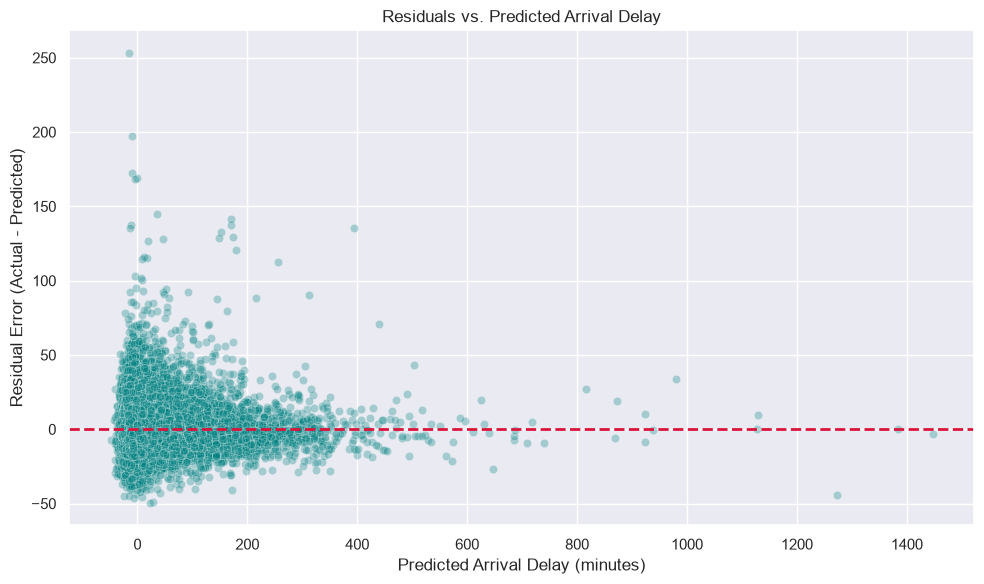

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
import numpy as np

gd_model = LinearRegressionGradientDescent(learning_rate=0.98, n_iterations=1000)
gd_model.fit(X_train_processed, y_train)

y_pred_train = gd_model.predict(X_train_processed)
y_pred_test = gd_model.predict(X_test_processed)

train_rmse = np.sqrt(mean_squared_error(y_train, y_pred_train))
test_rmse = np.sqrt(mean_squared_error(y_test, y_pred_test))
test_mae = mean_absolute_error(y_test, y_pred_test)
test_r2 = r2_score(y_test, y_pred_test)

print("\n Custom GD Model Advanced Evaluation")
print(f"Training RMSE:   {train_rmse:.2f} minutes")
print(f"Testing RMSE:    {test_rmse:.2f} minutes")
print(f"Testing MAE:     {test_mae:.2f} minutes")
print(f"Testing R-squared: {test_r2:.4f}\n")

residuals = y_test - y_pred_test

plt.figure(figsize=(10, 6))
sns.scatterplot(x=y_pred_test, y=residuals, alpha=0.3, color='teal')
plt.axhline(y=0, color='crimson', linestyle='--', linewidth=2)
plt.title('Residuals vs. Predicted Arrival Delay')
plt.xlabel('Predicted Arrival Delay (minutes)')
plt.ylabel('Residual Error (Actual - Predicted)')
plt.tight_layout()
plt.show()

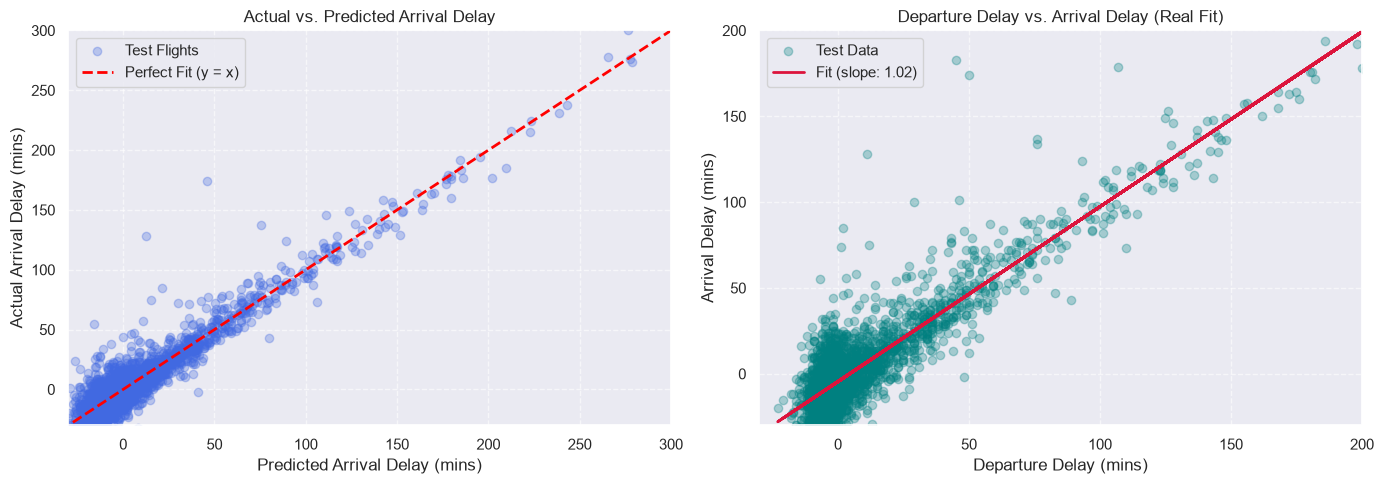

In [11]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sample_idx = np.random.choice(len(y_test), size=3000, replace=False)
axes[0].scatter(y_pred_test[sample_idx], y_test[sample_idx], alpha=0.3, color='royalblue', label='Test Flights')

min_val = min(y_pred_test[sample_idx].min(), y_test[sample_idx].min())
max_val = max(y_pred_test[sample_idx].max(), y_test[sample_idx].max())
axes[0].plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='Perfect Fit (y = x)')

axes[0].set_title('Actual vs. Predicted Arrival Delay')
axes[0].set_xlabel('Predicted Arrival Delay (mins)')
axes[0].set_ylabel('Actual Arrival Delay (mins)')
axes[0].set_xlim(-30, 300)
axes[0].set_ylim(-30, 300)
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend()

dep_delay = X_test['DEPARTURE_DELAY'].values[sample_idx]
arr_delay = y_test[sample_idx]

axes[1].scatter(dep_delay, arr_delay, alpha=0.3, color='teal', label='Test Data')

m_val, b_val = np.polyfit(dep_delay, arr_delay, 1)
axes[1].plot(dep_delay, m_val * dep_delay + b_val, color='crimson', linewidth=2, label=f'Fit (slope: {m_val:.2f})')

axes[1].set_title('Departure Delay vs. Arrival Delay (Real Fit)')
axes[1].set_xlabel('Departure Delay (mins)')
axes[1].set_ylabel('Arrival Delay (mins)')
axes[1].set_xlim(-30, 200)
axes[1].set_ylim(-30, 200)
axes[1].grid(True, linestyle='--', alpha=0.6)
axes[1].legend()

plt.tight_layout()
plt.show()